### Загрузка данных с продажами компьютерных игр

In [3]:
pip install kagglehub

  Using cached pyyaml-6.0.3-cp312-cp312-win_amd64.whl.metadata (2.4 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached certifi-2026.7.22-py3-none-any.whl.metadata (2.5 kB)
Using cached pyyaml-6.0.3-cp312-cp312-win_amd64.whl (154 kB)
Using cached requests-2.34.2-py3-none-any.whl (73 kB)
Using cached certifi-2026.7.22-py3-none-any.whl (136 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("gregorut/videogamesales")

print("Path to dataset files:", path)

c:\Users\Дарья\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 381k/381k [00:00<00:00, 523kB/s]

Extracting files...
Path to dataset files: C:\Users\Дарья\.cache\kagglehub\datasets\gregorut\videogamesales\versions\2


In [6]:
pip install pandas

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.7 MB 3.4 MB/s eta 0:00:03
   ------ --------------------------------- 1.6/9.7 MB 2.7 MB/s eta 0:00:03
   ------- -------------------------------- 1.8/9.7 MB 2.1 MB/s eta 0:00:04
   ----------- ---------------------------- 2.9/9.7 MB 2.8 MB/s eta 0:00:03
   ----------- ---------------------------- 2.9/9.7 MB 2.8 MB/s eta 0:00:03
   ---------------- ----------------------- 3.9/9.7 MB 2.7 MB/s eta 0:00:03
   ------------------ --------------------- 4.5/9.7 MB 2.8 MB/s eta 0:00:02
   ------------------- -------------------- 4.7/9.7 MB 2.7 MB/s eta 0:00:02
   ------------------- -------------------- 4.7/9.7 MB 2.7 MB/s eta 0:00:02
   ----------------------- ---------------- 5.8/9.7 MB 2.6 MB/s eta 0:00:02
   ----------------------- ------


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import pandas as pd

In [ ]:
import os
file_name = 'vgsales.csv'
full_path = os.path.join(path, file_name)

['vgsales.csv']


In [11]:
df = pd.read_csv(full_path)
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


### Разведка данных
Проверяем количество пропусков, выбросы

In [13]:
df.info()
df.describe()


<class 'pandas.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  str    
 2   Platform      16598 non-null  str    
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  str    
 5   Publisher     16540 non-null  str    
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), str(4)
memory usage: 1.4 MB


,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16327.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,2006.406443,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,5.828981,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


In [14]:
df["Year"].isna().sum()

np.int64(271)

### Выявляем топ жанров и авторов

In [21]:
df.groupby("Genre")["Global_Sales"].sum().sort_values(ascending=False).head(5)

Genre
Action          1751.18
Sports          1330.93
Shooter         1037.37
Role-Playing     927.37
Platform         831.37
Name: Global_Sales, dtype: float64

In [22]:
df.groupby("Publisher")["Name"].count().sort_values(ascending=False).head(5)

Publisher
Electronic Arts                 1351
Activision                       975
Namco Bandai Games               932
Ubisoft                          921
Konami Digital Entertainment     832
Name: Name, dtype: int64

In [26]:
!pip install matplotlib seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 578.7 kB/s eta 0:00:16
   -- ------------------------------------- 0.5/9.3 MB 578.7 kB/s eta 0:00:16
   --- ------------------------------------ 0.8/9.3 MB 671.3 kB/s eta 0:00:13
   ---- ----------------------------------- 1.0/9.3 MB 709.1 kB/s eta 0:00:12
   ----- ---------------------------------- 1.3/9.3 MB 808.5 kB/s eta 0:00:10
   ----- ---------------------------------- 1.3/9.3 MB 808.5 kB/s eta 0:00:10
   ------ --------------------------------- 1.6/9.3 MB 814.6 kB/s eta 0:00:10
   ------- -------------------------------- 1.8/9


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### Строим графики для наглядности

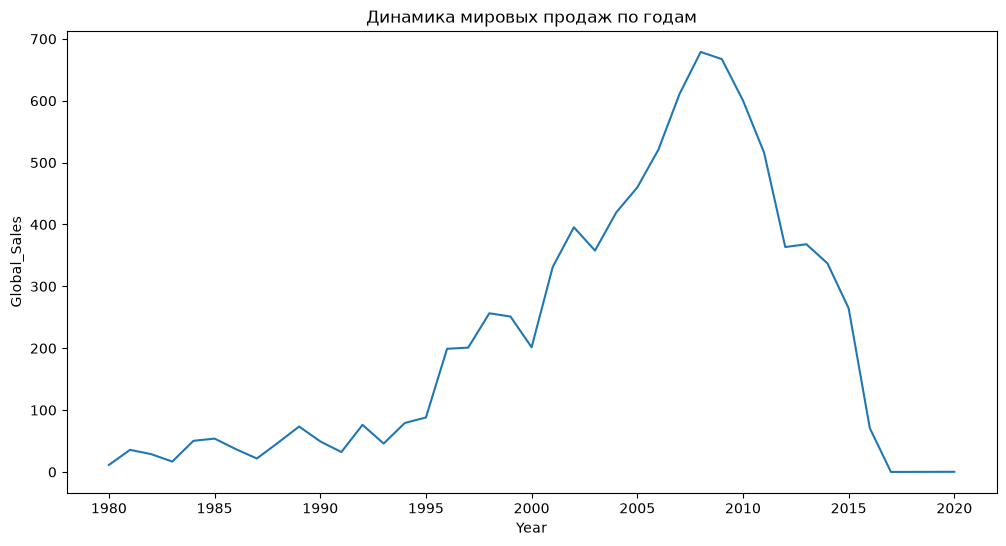

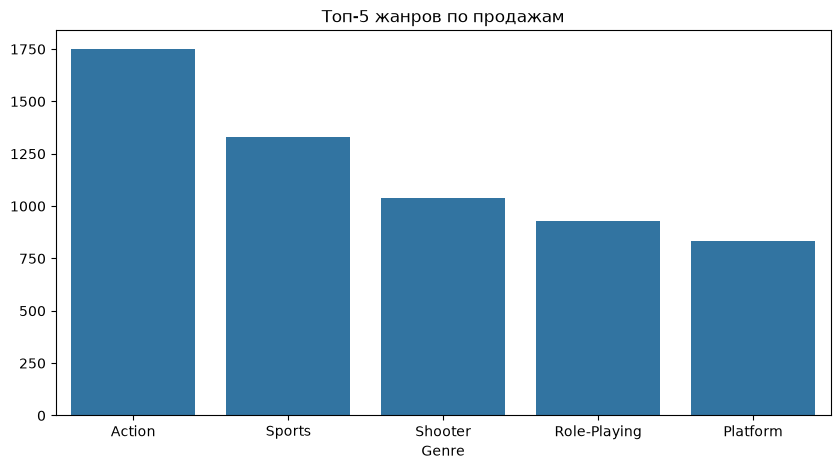

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


yearly_sales = df.groupby('Year')['Global_Sales'].sum()
plt.figure(figsize=(12,6))
sns.lineplot(data=yearly_sales)
plt.title('Динамика мировых продаж по годам')
plt.show()


top_genres = df.groupby('Genre')['Global_Sales'].sum().sort_values(ascending=False).head(5)
plt.figure(figsize=(10,5))
sns.barplot(x=top_genres.index, y=top_genres.values)
plt.title('Топ-5 жанров по продажам')
plt.show()

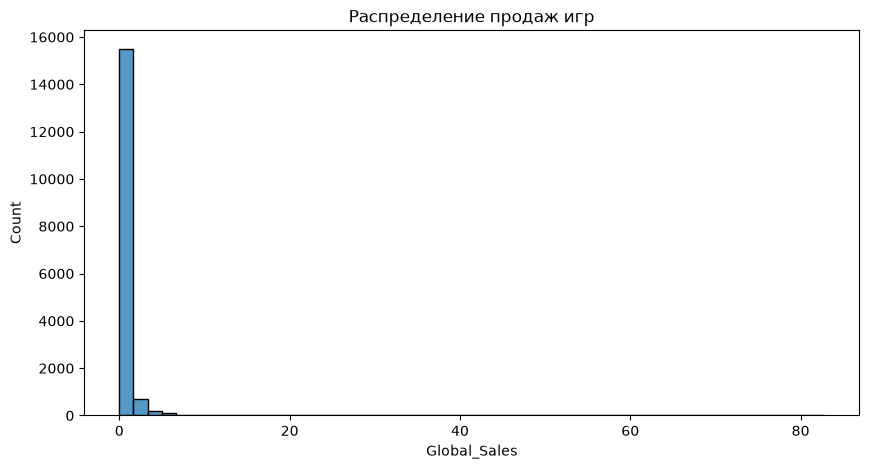

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(df['Global_Sales'], bins=50) 
plt.title('Распределение продаж игр')
plt.show()

### Выводы по графику
* Наблюдается стремительный рост продаж с 1905 по 2009г
* Резкий спад после 2015г связан скорее всего с неполнотой данных
* Action является безусловным лидером
* Sports и Shooter входит в топ-3, что показывает предпочтения рынка к активным игровым механикам

Проведём проверку, что null в стобике year не влияет на статистику

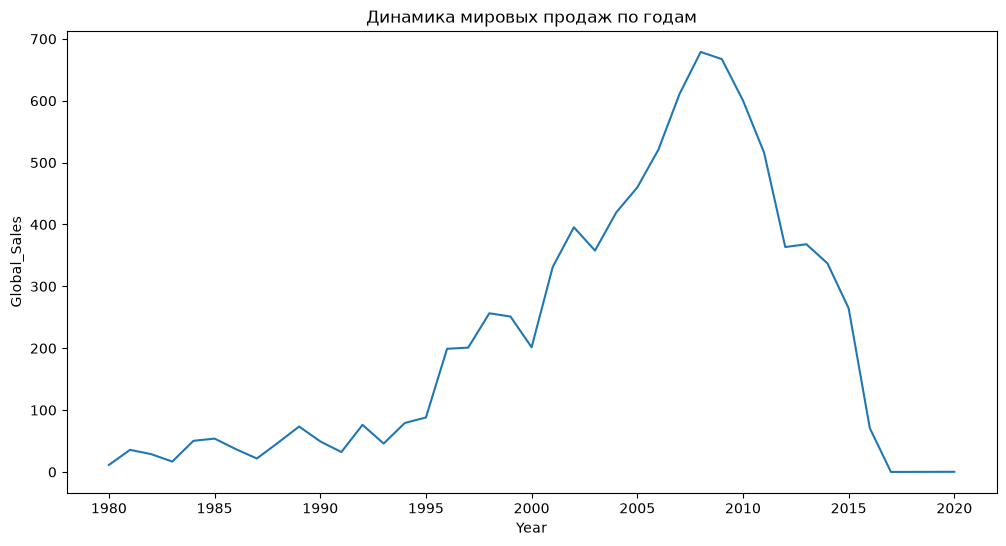

In [30]:
df = df.dropna(subset=['Year'])
yearly_sales = df.groupby('Year')['Global_Sales'].sum()
plt.figure(figsize=(12,6))
sns.lineplot(data=yearly_sales)
plt.title('Динамика мировых продаж по годам')
plt.show()

Делаем вывод, что пропуски были равномерное распределены или их слишком мало, чтобы изменить общую картинку